# 👕 PyTorch 실전 — 이미지 6만 장, FashionMNIST 옷 분류

**건축공학딥러닝프로그래밍 · PyTorch 실전 (FashionMNIST) · 실습 노트북 (완성본)**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_DL-AE/blob/main/PyTorch_FashionMNIST/fashion_mnist_practice.ipynb) ← **실습본**(빈칸 채우기) &nbsp;&nbsp;[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/baekja/Lecture_DL-AE/blob/main/PyTorch_FashionMNIST/fashion_mnist_complete.ipynb) ← **완성본**(정답·실행결과 포함)

> 지난 실습(XOR)에서는 데이터 **4개**, 가중치 **9개**짜리 신경망으로 강의노트의 손계산을 그대로 재현했습니다.
> 이번에는 옷 사진 **6만 장**을 보고 **10가지** 옷 종류를 맞히는 신경망(가중치 **669,706개**)을 학습시킵니다.
> 데이터와 신경망이 수만 배 커져도 **학습 루프 4단계는 그대로**라는 것을 직접 확인해 봅시다.

## 📌 강의 중점
- `Dataset` · `DataLoader` 로 이미지 6만 장을 **미니배치(64장)** 단위로 학습
- 다층 신경망(784 – 512 – 512 – 10) — `nn.Flatten` · `nn.Linear` · `nn.ReLU` · `nn.Sequential`
- 다중 분류: 로짓 → 소프트맥스 → 크로스 엔트로피(`CrossEntropyLoss`), 그리고 정확도
- 지난 실습과 **같은 학습 루프 4단계** · 학습률과 최적화기에 따른 성능 차이

## 🎯 학습 목표
1. FashionMNIST 이미지 한 장의 모양(`[1, 28, 28]`)과 값의 범위(0~1)를 확인하고, 정답 번호를 옷 이름으로 바꿀 수 있다.
2. `DataLoader` 의 배치 크기 · 섞기를 설정하고, 1 에포크의 업데이트 횟수(938번)를 계산할 수 있다.
3. 다층 신경망을 `nn.Module` 로 정의하고, 파라미터 수(669,706개)와 로짓 · 소프트맥스 · 크로스 엔트로피의 관계를 설명할 수 있다.
4. `train()` · `test()` 로 학습 · 평가하고, 학습률 · 최적화기를 바꿔 정확도를 약 71 % → 약 88 % 로 높일 수 있다.

## 📋 이 노트북 사용법

| 표시 | 뜻 |
|:-:|---|
| ▶ | 셀 실행 — 셀을 클릭하고 `Shift + Enter` |
| 🎬 EP*n* | 이 부분을 설명하는 강의 영상 에피소드 (e-campus) |
| ⏸ | 영상을 멈추고 직접 실행해 보는 지점 |
| ✅ / ❌ | 자가검증 결과 — ❌ 가 나오면 힌트를 읽고 고쳐 보세요 |
| 🔸 | 오류가 아니라 실험 결과 표시(틀린 예측 사례 등) |
| ⏱ | 걸린 시간 — 학습 셀은 1~2분씩 걸립니다 |

**주석(`#` 뒤의 글) 읽는 법** — 실행에는 영향이 없는 설명입니다.
- `①②③`, `1️⃣2️⃣3️⃣4️⃣` 순서(단계) · `💡` 이론 연결(인공신경망 이론 강의) · `📐` 데이터 모양(shape) · `⚠️` 흔한 실수 · `✅` 기대 결과 · `🎲` 랜덤 씨앗(재현용)

**Colab에서 처음 열었다면**
1. 메뉴 **파일 → Drive에 사본 저장** 을 먼저 누르세요. (사본에서 작업해야 내 Drive에 저장됩니다)
2. 런타임은 기본(CPU) 그대로 두어도 됩니다. 학습 셀이 1~2분씩 걸리는데, 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 를 고르면 더 빨라집니다. 코드는 CPU · GPU 어느 쪽에서도 그대로 실행됩니다.
3. 위에서부터 **차례대로** 실행하세요. 런타임이 초기화되어 변수가 사라지면 처음부터 다시 실행하면 됩니다.

**🎬 영상과 함께 보는 법 (반복 학습 추천 순서)**
1회차 영상 전체 보기 → 2회차 실습본을 열고 ⏸ 마다 멈추며 따라 치기 → 3회차 영상 없이 빈칸 채우기 → 모든 ✅ 통과 → 6장 도전 과제

---
## 0. 준비 — 라이브러리 불러오기  🎬 EP1

이 셀에서 할 일: PyTorch와 데이터 도구를 불러오고, 숫자를 보기 좋게 출력하도록 설정합니다.

> 💡 **새 파이썬 문법 — `from 상자 import 도구`**
> 도구 상자(라이브러리)에서 **필요한 도구만** 꺼내 옵니다. 지난 실습의 `import torch` 는 상자를 통째로 가져와 `torch.이름` 으로 썼죠.
> `from torchvision.transforms import ToTensor` 로 가져오면 긴 이름 없이 `ToTensor` 로 바로 씁니다.

In [1]:
import torch                                  # PyTorch: 딥러닝 도구 상자
from torch import nn                          # nn = 신경망(neural network) 부품 모음
from torch.utils.data import DataLoader       # 데이터를 배치로 묶어 나르는 도구
from torchvision import datasets              # 이미지 데이터셋 모음 (FashionMNIST 포함)
from torchvision.transforms import ToTensor   # 이미지 → 텐서 변환 도구
import matplotlib.pyplot as plt               # 그래프 도구 (별명 plt)
import math                                   # 수학 도구 (ln 계산)
import os                                     # 파일 도구 (파일 크기 확인)
import time                                   # 시간 재기 ⏱

torch.set_printoptions(precision=4, sci_mode=False)  # 소수 4자리, 지수 표기 끄기
print("PyTorch 버전:", torch.__version__)            # Colab에는 이미 설치됨

PyTorch 버전: 2.9.1


### 0-1. 계산 장치 고르기 — CPU 또는 GPU
GPU(그래픽카드)는 행렬 계산을 한꺼번에 많이 해 주는 계산기입니다. 이 노트북은 **GPU가 없어도(CPU만으로도)** 그대로 실행됩니다.

> 💡 **새 파이썬 문법 — `A if 조건 else B`**
> 조건이 참이면 A, 거짓이면 B 를 고르는 한 줄짜리 if 입니다. `torch.cuda.is_available()` 은 "GPU(cuda)를 쓸 수 있나요?" 에 True / False 로 답합니다.

In [2]:
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU 있으면 cuda, 없으면 cpu
print("사용 장치:", device)                              # Colab 기본 = cpu, T4 GPU = cuda

사용 장치: cpu


### 자가검증 도우미 `check()` · `check_range()` 준비
아래 두 셀은 결과가 맞는지 ✅ / ❌ 로 알려 주는 **도우미 함수**입니다. 지난 실습과 같은 `check()` 에, 정확도처럼 **범위**로 확인할 값을 위한 `check_range()` 를 더했습니다.
지금은 내용을 몰라도 괜찮습니다 — **실행만** 해 두세요.

In [3]:
def check(name, value, expected, tol=0.01):  # 자가검증 (이름, 결과, 기대값, 허용오차)
    """value 가 expected 와 tol 이내로 같으면 ✅, 다르면 ❌ 를 보여 줍니다."""
    value = torch.as_tensor(value, dtype=torch.float32)        # 숫자·리스트 → 텐서
    expected = torch.as_tensor(expected, dtype=torch.float32)  # 기대값도 텐서로
    if value.shape != expected.shape:                          # ⚠️ 모양부터 다르면
        print(f"❌ {name}: 모양 {tuple(value.shape)} ≠ 기대 {tuple(expected.shape)}")
        return                                                 # 여기서 끝
    gap = (value - expected).abs().max().item()                # 가장 큰 차이
    mark = "✅" if gap <= tol else "❌"                         # 허용오차 안이면 통과
    tol_s = f"{tol:.6f}".rstrip("0").rstrip(".")               # 0.000001 처럼 보기 좋게
    print(f"{mark} {name}: 최대 차이 {gap:.6f} (허용 {tol_s})")  # 결과 출력

In [4]:
def check_range(name, value, lo, hi):  # 자가검증 (이름, 결과, 아래 한계, 위 한계)
    """value 가 lo 이상 hi 이하이면 ✅, 벗어나면 ❌ 를 보여 줍니다."""
    value = float(value)                                       # 텐서·정수 → 숫자 하나
    mark = "✅" if lo <= value <= hi else "❌"                  # 범위 안이면 통과
    print(f"{mark} {name}: {value:.4f} (기대 범위 {lo} ~ {hi})")  # 결과 출력

---
## 1. Dataset — 옷 사진 6만 장 불러오기  🎬 EP1

**FashionMNIST** 는 옷 · 신발 · 가방 사진 7만 장을 모은 데이터셋입니다. (학습용 6만 장 + 시험용 1만 장, 10가지 종류)
- 사진 한 장 = 가로 28 × 세로 28 픽셀의 흑백 이미지
- `Dataset` = 번호를 주면 **(이미지, 정답 번호)** 한 쌍을 꺼내 주는 상자
- `transform=ToTensor()` = 꺼낼 때마다 이미지를 텐서(숫자 상자)로 바꿔 주는 변환

처음 실행하면 인터넷에서 약 30 MB 를 내려받아 `data` 폴더에 저장합니다. (수십 초 · 진행 막대가 보이면 정상)

> 💡 **새 파이썬 문법 — `이름=값` (키워드 인자)**
> 함수를 부를 때 `train=True` 처럼 **이름을 붙여** 값을 넘기면, 순서를 외우지 않아도 되고 읽기도 쉽습니다.

In [5]:
training_data = datasets.FashionMNIST(  # 학습용 데이터셋
    root="data",                        # 저장할 폴더
    train=True,                         # True = 학습용 (6만 장)
    download=True,                      # 폴더에 없으면 내려받기
    transform=ToTensor(),               # 이미지 → 텐서(숫자 상자)로
)                                       # (괄호 닫기)
test_data = datasets.FashionMNIST(      # 시험용 데이터셋
    root="data", train=False,           # False = 시험용 (1만 장)
    download=True, transform=ToTensor(),  # 학습용과 같은 변환
)                                       # (괄호 닫기)
print("학습 데이터:", len(training_data), "장")   # len() = 개수
print("테스트 데이터:", len(test_data), "장")     # 학습에 쓰지 않는 시험용
check("학습 데이터 수", len(training_data), 60000, tol=0)  # ✅ 6만 장
check("테스트 데이터 수", len(test_data), 10000, tol=0)    # ✅ 1만 장

학습 데이터: 60000 장
테스트 데이터: 10000 장
✅ 학습 데이터 수: 최대 차이 0.000000 (허용 0)
✅ 테스트 데이터 수: 최대 차이 0.000000 (허용 0)


🔍 **결과 읽는 법** — 학습용 60,000 장, 시험용 10,000 장입니다. 시험용은 학습에 **한 번도 쓰지 않고** 마지막에 실력을 재는 데만 씁니다. 시험 문제를 미리 보고 공부하면 진짜 실력을 알 수 없으니까요.

> ⚠️ **흔한 실수** — `transform=ToTensor()` 를 빠뜨리면 이미지가 사진(PIL 이미지) 그대로 나와서, 신경망에 넣을 때 오류가 납니다.

### 1-1. 한 장 꺼내 보기 — 이미지도 숫자 상자(텐서)
`training_data[0]` 처럼 번호를 주면 (이미지, 정답 번호) 한 쌍이 나옵니다.

> 💡 **새 파이썬 문법 — 한 번에 두 개 받기 `img, label = …`**
> 값 두 개가 짝으로 나오면, 왼쪽에 이름 두 개를 쉼표로 적어 한 번에 나눠 받습니다.

In [6]:
img, label = training_data[0]                   # 0번 샘플 = (이미지, 정답 번호)
print("이미지 모양:", img.shape)       # 📐 채널 × 세로 × 가로
print("자료형:", img.dtype)                     # float32 = 실수
print("값 범위:", img.min().item(), "~", img.max().item())  # 0(검정) ~ 1(흰색)
print("정답 번호:", label)                      # 0~9 중 하나 (이름은 다음 셀에서)
print("픽셀 4×4 조각:\n", img[0, 12:16, 10:14])  # 이미지도 결국 숫자 표!
check("이미지 모양", img.shape, (1, 28, 28), tol=0)  # ✅
check_range("가장 어두운 픽셀", img.min(), 0, 1)    # ✅ 0 이상
check_range("가장 밝은 픽셀", img.max(), 0, 1)      # ✅ 1 이하

이미지 모양: torch.Size([1, 28, 28])
자료형: torch.float32
값 범위: 0.0 ~ 1.0
정답 번호: 9
픽셀 4×4 조각:
 tensor([[0.0235, 0.0000, 0.3882, 0.9569],
        [0.0000, 0.0000, 0.2157, 0.9255],
        [0.0000, 0.0000, 0.9294, 0.8863],
        [0.5686, 0.8000, 0.8941, 0.8118]])
✅ 이미지 모양: 최대 차이 0.000000 (허용 0)
✅ 가장 어두운 픽셀: 0.0000 (기대 범위 0 ~ 1)
✅ 가장 밝은 픽셀: 1.0000 (기대 범위 0 ~ 1)


🔍 **결과 읽는 법**
- `[1, 28, 28]` = 채널 1개(흑백) × 세로 28 × 가로 28 → 픽셀 **784개**. (컬러 사진이라면 채널이 3개(RGB))
- 픽셀 값은 0(검정) ~ 1(흰색). 원래 0~255 정수였는데 `ToTensor()` 가 255 로 나눠 0~1 실수로 바꿨습니다. 조각 속 0 은 배경, 0.9 근처는 밝은 부분입니다.
- 정답은 이름이 아니라 **번호(0~9)** 입니다. 위의 `9` 는 무엇일까요? → 다음 셀

### 1-2. 정답 번호 → 옷 이름

| 번호 | 이름 | 뜻 | | 번호 | 이름 | 뜻 |
|:-:|---|---|---|:-:|---|---|
| 0 | T-shirt/top | 티셔츠 | | 5 | Sandal | 샌들 |
| 1 | Trouser | 바지 | | 6 | Shirt | 셔츠 |
| 2 | Pullover | 스웨터 | | 7 | Sneaker | 운동화 |
| 3 | Dress | 원피스 | | 8 | Bag | 가방 |
| 4 | Coat | 코트 | | 9 | Ankle boot | 앵클부츠 |

> 💡 **새 파이썬 문법 — f-문자열 `f"…{변수}…"`**
> 따옴표 앞에 `f` 를 붙이면 `{ }` 안에 변수 값이 들어갑니다. `{acc:.1%}` 처럼 `:` 뒤에 모양을 정하면 0.7115 → `71.2%` 처럼 보기 좋게 바뀝니다.

In [7]:
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",  # 0~4
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]      # 5~9
print(f"정답 번호 {label} → {class_names[label]}")    # 번호로 이름 찾기 (리스트 인덱스)
print("데이터셋의 이름표와 같은가?", class_names == training_data.classes)  # True
check("클래스 수", len(class_names), 10, tol=0)        # ✅ 10가지 옷 종류

정답 번호 9 → Ankle boot
데이터셋의 이름표와 같은가? True
✅ 클래스 수: 최대 차이 0.000000 (허용 0)


### 1-3. 9장 구경하기 (3 × 3)
> 💡 **새 파이썬 문법 — `for i, ax in enumerate(…)`**
> `enumerate` 는 하나씩 꺼내면서 **번호(0, 1, 2, …)도 함께** 붙여 줍니다. 그림 칸(`ax`) 9개에 0~8번 사진을 차례로 그립니다.

(그림을 그리는 코드입니다 — 결과 그림만 보셔도 됩니다)

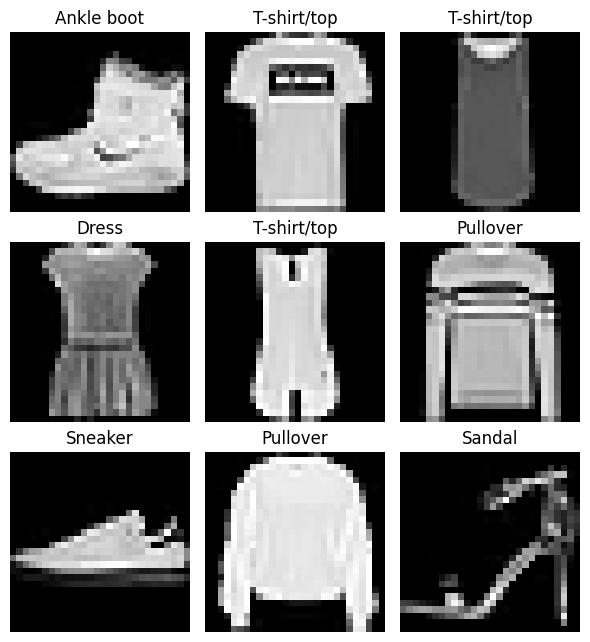

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(6, 6.5))  # 3×3 칸의 그림판
for i, ax in enumerate(axes.flat):                # 9칸에 차례로 (i = 0~8)
    img, label = training_data[i]                 # i번 샘플 꺼내기
    ax.imshow(img.squeeze(), cmap="gray")         # 📐 (1, 28, 28) → (28, 28) 흑백 그림
    ax.set_title(class_names[label])              # 제목 = 옷 이름 (영어)
    ax.axis("off")                                # 눈금 숨기기
plt.tight_layout()                                # 간격 정리
plt.show()                                        # 그리기

🔍 **결과 읽는 법** — 28 × 28 이라 흐릿하지만 사람은 대부분 알아봅니다. 신경망은 이 **784개의 숫자만** 보고 맞혀야 합니다. 티셔츠 · 셔츠 · 스웨터 · 코트는 사람이 봐도 헷갈리죠? 🔎 6장에서 신경망도 같은 곳에서 헷갈리는지 확인합니다.
(`squeeze()` 는 크기가 1인 차원을 없애 `[1, 28, 28]` → `[28, 28]` 로 만듭니다. 그림 도구는 2차원 표를 받기 때문입니다)

**📝 1분 퀴즈** ① 이미지 한 장의 픽셀은 몇 개? ② `training_data[0]` 은 무엇을 돌려주나요?
<details><summary>정답 보기</summary>

① 28 × 28 = **784개** ② **(이미지 텐서, 정답 번호)** 한 쌍 — 이미지 모양은 `[1, 28, 28]`, 정답은 0~9 의 번호
</details>

---
## 2. DataLoader와 미니배치 — 64장씩 묶어 나르기  🎬 EP2

지난 실습(XOR)에서 업데이트 방식 두 가지를 비교했습니다. 데이터가 6만 장이라면 어떨까요?

| 방식 | 1번 업데이트에 쓰는 데이터 | 1 에포크의 업데이트 횟수 | 6만 장일 때 |
|---|:-:|:-:|---|
| 한 샘플씩 (온라인, XOR 5장) | 1개 | 60,000 번 | 느리고 많이 흔들림 |
| 한꺼번에 (배치, XOR 6-1) | 60,000개 | 1 번 | 메모리 부담, 업데이트가 너무 드묾 |
| **미니배치 (오늘)** | **64개** | **938 번** | 둘의 중간 — 가장 많이 쓰는 방식 |

> 💡 이론 강의의 **Batch size** = 1회 업데이트에 사용하는 데이터 수, **Epoch** = 전체 데이터를 한 바퀴 학습하는 단위

`DataLoader` 는 Dataset 에서 `batch_size` 장씩 꺼내 **묶음(배치)** 으로 만들어 주는 컨베이어 벨트입니다.
- `shuffle=True` : 에포크마다 순서를 **섞어서** 꺼냅니다 (학습용만)
- `generator=g` : 섞는 순서의 랜덤 씨앗 🎲 — 누가 실행해도 영상 · 완성본과 같은 결과가 나오게 합니다

In [9]:
batch_size = 64                       # 한 번에 묶는 장 수
g = torch.Generator().manual_seed(0)  # 🎲 섞는 순서의 씨앗 (재현용)
train_dataloader = DataLoader(training_data,     # 학습용 데이터셋을
                              batch_size=batch_size,  # 배치 크기만큼 묶고
                              shuffle=True,      # 에포크마다 섞어서
                              generator=g)       # (섞는 순서는 씨앗 g 로)
test_dataloader = DataLoader(test_data, batch_size=batch_size)  # 시험용: 섞지 않음
print("학습 배치 수:", len(train_dataloader))     # 학습용 배치 개수
print("테스트 배치 수:", len(test_dataloader))    # 시험용 배치 개수
check("1 에포크의 업데이트 횟수", len(train_dataloader), 938, tol=0)  # ✅ 배치 수

학습 배치 수: 938
테스트 배치 수: 157
✅ 1 에포크의 업데이트 횟수: 최대 차이 0.000000 (허용 0)


🔍 **결과 읽는 법** — 60,000 ÷ 64 = 937.5 → 64장짜리 배치 937개 + 마지막 배치 1개 = **938개**. 배치 하나마다 가중치를 한 번 고치므로, 1 에포크에 **938번** 업데이트합니다. (시험용 10,000 장은 배치 157개)

> ⚠️ **흔한 실수** — 학습용은 꼭 섞으세요(`shuffle=True`). 데이터가 종류별로 모여 있으면 한 종류만 연달아 배우다가 앞에서 배운 것을 잊어버립니다. 시험용은 순서가 결과에 영향이 없어서 섞지 않습니다.

### 2-1. 배치 하나 꺼내 보기
> 💡 **새 파이썬 문법 — `next(iter(…))`**
> `iter()` 는 "꺼낼 준비", `next()` 는 "다음 것 하나 꺼내기" 입니다. 컨베이어 벨트에서 **첫 묶음만** 꺼내 볼 때 씁니다.

In [10]:
X, y = next(iter(train_dataloader))  # 학습용 벨트에서 첫 배치 하나만
print("X 모양:", X.shape)            # 📐 [64, 1, 28, 28] = [배치, 채널, 세로, 가로]
print("y 모양:", y.shape, y.dtype)   # 📐 [64], int64 = 정수 (정답 번호 64개)
print("정답 앞 10개:", y[:10])       # 섞였으므로 0~9 가 뒤죽박죽
check("X 모양", X.shape, (64, 1, 28, 28), tol=0)  # ✅
check("y 모양", y.shape, (64,), tol=0)            # ✅

X 모양: torch.Size([64, 1, 28, 28])
y 모양: torch.Size([64]) torch.int64
정답 앞 10개: tensor([0, 7, 3, 6, 2, 1, 9, 4, 4, 4])
✅ X 모양: 최대 차이 0.000000 (허용 0)
✅ y 모양: 최대 차이 0.000000 (허용 0)


🔍 **결과 읽는 법**
- `X` : `[64, 1, 28, 28]` = **[배치, 채널, 세로, 가로]**. 지난 실습의 `X` 는 `[4, 2]` (샘플 4개 × 입력 2개)였죠. 맨 앞 숫자가 **샘플(이미지) 수**인 것은 같습니다.
- `y` : `[64]` 모양의 **정수(int64)** — 정답 번호 64개입니다. 지난 실습처럼 `(4, 1)` 모양의 실수가 아닙니다. 다중 분류의 비용함수 `CrossEntropyLoss` 는 정답을 **번호 그대로** 받습니다. (3-5)

### 2-2. 1 에포크 = 배치 938개 — 마지막 배치는 몇 장?
`for 이미지, 정답 in train_dataloader:` 로 반복하면 배치를 처음부터 끝까지 하나씩 꺼냅니다. 이 한 바퀴가 바로 **1 에포크**입니다.
학습은 하지 않고 꺼내기만 하면서 배치 크기를 세어 봅시다. ⏸ 몇 초 걸립니다.

In [11]:
start = time.time()                            # ⏱ 시작 시각 (초)
sizes = []                                     # 배치마다 장 수를 기록할 목록
for images, labels in train_dataloader:        # 배치를 처음부터 끝까지 한 바퀴
    sizes.append(len(labels))                  # 이번 배치의 장 수
print("배치 수:", len(sizes))                  # 938개
print("처음 3개:", sizes[:3], "· 마지막:", sizes[-1])  # [64, 64, 64] · 32
print("합계:", sum(sizes), "장")               # 60000 장 = 1 에포크
print(f"⏱ 꺼내기만 {time.time() - start:.1f}초")  # 학습 없이 데이터만 꺼낸 시간
check("마지막 배치 크기", sizes[-1], 32, tol=0)      # ✅ 60000 − 937 × 64 = 32
check("1 에포크 = 6만 장", sum(sizes), 60000, tol=0)  # ✅

배치 수: 938
처음 3개: [64, 64, 64] · 마지막: 32
합계: 60000 장
⏱ 꺼내기만 1.9초
✅ 마지막 배치 크기: 최대 차이 0.000000 (허용 0)
✅ 1 에포크 = 6만 장: 최대 차이 0.000000 (허용 0)


🔍 **결과 읽는 법** — 64장짜리 배치 937개와 32장짜리 마지막 배치 1개, 합계 6만 장입니다. 10 에포크를 학습하면 업데이트는 938 × 10 = **9,380번**입니다. 지난 실습(XOR)의 4만 번보다 적지만, 한 번에 64장씩 보기 때문에 훨씬 많은 데이터를 봅니다.
꺼내기만 해도 몇 초 걸리죠? 학습할 때는 여기에 계산 시간이 더해집니다.

**📝 1분 퀴즈** ① `batch_size=100` 이면 1 에포크의 업데이트 횟수는? ② 배치 `X` 의 모양 `[64, 1, 28, 28]` 에서 맨 앞의 64 는?
<details><summary>정답 보기</summary>

① 60,000 ÷ 100 = **600번** (나누어떨어지므로 마지막 배치도 100장) ② **배치 크기** — 한 번에 묶은 이미지 장 수
</details>

---
## 3. 신경망 모델 — 784 → 512 → 512 → 10  🎬 EP3

강의노트의 신경망입니다. 지난 실습의 2 – 2 – 1 신경망과 **뼈대는 같고 크기만 커졌습니다.**

| 층 | 노드 수 | 하는 일 | 지난 실습(XOR) |
|---|:-:|---|---|
| 입력층 | 784 | 28 × 28 이미지를 한 줄로 펼친 픽셀 값 (`nn.Flatten`) | 입력 2개 |
| 은닉층 1 | 512 | `nn.Linear(784, 512)` + **ReLU** | 은닉노드 2개 + 시그모이드 |
| 은닉층 2 | 512 | `nn.Linear(512, 512)` + **ReLU** | (없음) |
| 출력층 | 10 | `nn.Linear(512, 10)` → 클래스마다 점수 1개 (**로짓**) | 출력 1개 + 시그모이드 |

> 💡 이론 강의: 출력노드의 수 = 범주(클래스)의 개수. 다중 분류는 출력에 **소프트맥스**를 씌워 확률로 바꿉니다. (3-4)

### 3-1. 활성화 함수 ReLU — 시그모이드 대신
ReLU 는 **음수는 0, 양수는 그대로** 내보내는 함수입니다: $\mathrm{ReLU}(z) = \max(0, z)$
계산이 간단하고, 층이 깊어져도 기울기가 잘 전달되어 학습이 잘 됩니다. (자세한 이유는 이론 시간의 '심층신경망'에서 다룹니다)

In [12]:
z = torch.tensor([-2.0, -0.5, 0.0, 1.5, 3.0])  # 예시 입력 5개 (음수 · 0 · 양수)
relu = nn.ReLU()                               # ReLU 부품 하나 만들기
print("ReLU(z)    =", relu(z))                 # 음수 → 0, 양수 → 그대로
print("sigmoid(z) =", torch.sigmoid(z))        # 비교: 지난 실습의 시그모이드 (0~1)
check("ReLU(z) = max(0, z)", relu(z), [0.0, 0.0, 0.0, 1.5, 3.0], tol=0)  # ✅

ReLU(z)    = tensor([0.0000, 0.0000, 0.0000, 1.5000, 3.0000])
sigmoid(z) = tensor([0.1192, 0.3775, 0.5000, 0.8176, 0.9526])
✅ ReLU(z) = max(0, z): 최대 차이 0.000000 (허용 0)


### 3-2. 설계도(class) 그리기
지난 실습 4장의 `XORNet` 과 같은 모양의 설계도입니다. 새 부품은 두 가지입니다.
- `nn.Flatten()` : `[N, 1, 28, 28]` → `[N, 784]` — 이미지를 한 줄로 **펼치기** (N = 배치 크기)
- `nn.Sequential(층1, 층2, …)` : 층을 **순서대로 이어 붙인** 묶음 (지난 실습 6-4 에서 잠깐 봤죠)

> ⚠️ `forward` 의 마지막에 소프트맥스를 넣지 않습니다. 출력은 점수(**로짓**) 그대로 — 소프트맥스는 비용함수 `CrossEntropyLoss` 안에 들어 있습니다. (3-5)

In [13]:
class NeuralNetwork(nn.Module):                  # 옷 분류 신경망 설계도 (nn.Module 상속)
    def __init__(self):                          # 부품 준비 (모델을 만들 때 1번 실행)
        super().__init__()                       # 부모(nn.Module) 준비 — 항상 맨 먼저
        self.flatten = nn.Flatten()              # 📐 → [N, 784] 한 줄로
        self.linear_relu_stack = nn.Sequential(  # 층을 순서대로 이어 붙이기
            nn.Linear(28*28, 512),               # 입력층 → 은닉층1
            nn.ReLU(),                           # 활성화 함수
            nn.Linear(512, 512),                 # 은닉층1 512 → 은닉층2 512
            nn.ReLU(),                           # 활성화 함수
            nn.Linear(512, 10),                  # 은닉층2 → 출력층
        )                                        # Sequential 끝

    def forward(self, x):                        # 순전파: 입력 x 가 지나가는 길
        x = self.flatten(x)                      # ① 이미지 펼치기
        logits = self.linear_relu_stack(x)       # ② 층 5개 통과 → 클래스 점수 10개
        return logits                            # 로짓(점수) 돌려주기 — 소프트맥스 전

### 3-3. 모델 만들기 — 가중치는 몇 개?
`torch.manual_seed(0)` 로 랜덤 씨앗을 고정하면 누가 실행해도 같은 초기 가중치가 나옵니다 (지난 실습 6-3). `.to(device)` 는 모델의 가중치를 계산 장치(CPU 또는 GPU)로 보냅니다.

In [14]:
torch.manual_seed(0)                  # 🎲 랜덤 씨앗 고정 → 누가 실행해도 같은 초기 가중치
model = NeuralNetwork().to(device)    # 설계도로 모델 생성 → 계산 장치로 보내기
print(model)                          # 구조: Flatten → Linear → ReLU → … → Linear

NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


In [15]:
for name, p in model.named_parameters():      # 파라미터 묶음마다
    print(name, tuple(p.shape), p.numel())    # 이름, 모양, 개수
n = 0                                         # 전체 개수 세기 (지난 실습과 같은 방법)
for p in model.parameters():                  # 파라미터 묶음마다
    n = n + p.numel()                         # 원소 개수(numel)를 더하기
print(f"전체 파라미터: {n:,}개")               # 세 자리마다 쉼표
# 💡 층마다 (입력 수 × 출력 수 + 편향 수) 를 더한 값
by_hand = (784 * 512 + 512) + (512 * 512 + 512) + (512 * 10 + 10)  # 세 층의 합
check("파라미터 개수 = 손으로 센 값", n, by_hand, tol=0)  # ✅
check("파라미터 개수 = 669,706", n, 669706, tol=0)        # ✅ 지난 실습은 9개!

linear_relu_stack.0.weight (512, 784) 401408
linear_relu_stack.0.bias (512,) 512
linear_relu_stack.2.weight (512, 512) 262144
linear_relu_stack.2.bias (512,) 512
linear_relu_stack.4.weight (10, 512) 5120
linear_relu_stack.4.bias (10,) 10
전체 파라미터: 669,706개
✅ 파라미터 개수 = 손으로 센 값: 최대 차이 0.000000 (허용 0)
✅ 파라미터 개수 = 669,706: 최대 차이 0.000000 (허용 0)


🔍 **결과 읽는 법**

| PyTorch 이름 | 모양 | 개수 | 뜻 |
|---|:-:|--:|---|
| `linear_relu_stack.0.weight` | (512, 784) | 401,408 | 입력 → 은닉층 1 가중치 |
| `linear_relu_stack.0.bias` | (512,) | 512 | 은닉층 1 편향 |
| `linear_relu_stack.2.weight` | (512, 512) | 262,144 | 은닉층 1 → 2 가중치 |
| `linear_relu_stack.2.bias` | (512,) | 512 | 은닉층 2 편향 |
| `linear_relu_stack.4.weight` | (10, 512) | 5,120 | 은닉층 2 → 출력 가중치 |
| `linear_relu_stack.4.bias` | (10,) | 10 | 출력 편향 |

- 번호가 0, 2, 4 인 이유: 1, 3 번은 ReLU — 가중치가 없는 부품이라 목록에 나오지 않습니다.
- 가중치 모양은 지난 실습처럼 **(출력 수, 입력 수)** 입니다.
- 지난 실습 **9개** → 오늘 **669,706개**. 그중 60 % 가 첫 층(784 × 512)에 있습니다. 하나하나 손으로 고칠 수는 없겠죠? 그래서 `backward()` 와 옵티마이저가 필요합니다.

### 3-4. 배치 하나 통과시키기 — 점수(로짓) → 확률(소프트맥스)
2-1 에서 꺼낸 배치(64장)를 모델에 넣어 봅니다. 아직 **학습 전**입니다.

In [16]:
X, y = X.to(device), y.to(device)            # 2-1 의 첫 배치를 모델과 같은 장치로
flat = model.flatten(X)                      # ① 펼치기만 따로 해 보기
print("펼친 모양:", flat.shape)              # 📐 [64, 1, 28, 28] → [64, 784]
with torch.no_grad():                        # 구경만 할 때는 미분 추적 끄기
    logits = model(X)                        # 순전파: 64장 → 장마다 점수 10개
print("logits 모양:", logits.shape)          # 📐 [64, 10]
print("첫 이미지의 점수 10개:\n", logits[0])  # 학습 전 → 0 근처의 작은 수 (음수도 있음)
check("펼친 모양", flat.shape, (64, 784), tol=0)     # ✅ 28 × 28 = 784
check("logits 모양", logits.shape, (64, 10), tol=0)  # ✅ 64장 × 클래스 10개

펼친 모양: torch.Size([64, 784])
logits 모양: torch.Size([64, 10])
첫 이미지의 점수 10개:
 tensor([ 0.1060,  0.1267,  0.0688,  0.0067, -0.0701, -0.1281, -0.0695, -0.0268,
         0.0292,  0.0884])
✅ 펼친 모양: 최대 차이 0.000000 (허용 0)
✅ logits 모양: 최대 차이 0.000000 (허용 0)


출력 `logits` 는 이미지마다 **점수 10개**입니다. 점수는 음수도 되고 합이 1 도 아니라서 확률로 읽을 수 없습니다. 이론 강의의 **소프트맥스**가 점수를 확률로 바꿉니다.

$$ s_i = \frac{e^{z_i}}{\sum_{j} e^{z_j}} \quad (i = 0, 1, \dots, 9) $$

예측은 **점수(또는 확률)가 가장 큰 클래스**입니다 → `argmax`

In [17]:
probs = logits.softmax(dim=1)                # 💡 소프트맥스: 행마다 점수 10개 → 확률 10개
print("첫 이미지의 확률 10개:\n", probs[0])   # 학습 전 → 모두 약 0.1
print("확률의 합:", probs[0].sum().item())   # 1.0
pred = logits.argmax(1)                      # 행마다 가장 큰 점수의 번호 = 예측 클래스
print("예측 앞 10개:", pred[:10].tolist())   # 학습 전이라 엉터리
print("정답 앞 10개:", y[:10].tolist())      # 비교해 보기
# .cpu(): GPU 에 있는 결과를 CPU 로 가져와 비교 (CPU 라면 그대로)
check("64장 모두 확률의 합 = 1", probs.sum(dim=1).cpu(), torch.ones(64), tol=1e-5)  # ✅

첫 이미지의 확률 10개:
 tensor([0.1094, 0.1117, 0.1054, 0.0990, 0.0917, 0.0865, 0.0918, 0.0958, 0.1013,
        0.1075])
확률의 합: 1.0
예측 앞 10개: [1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
정답 앞 10개: [0, 7, 3, 6, 2, 1, 9, 4, 4, 4]
✅ 64장 모두 확률의 합 = 1: 최대 차이 0.000000 (허용 0.00001)


🔍 **결과 읽는 법** — 학습 전이라 확률이 모두 약 0.1 (10개 중 하나를 찍는 수준)이고, 예측도 엉터리입니다.
- `dim=1` = "행마다(이미지마다) 가로 방향으로 10개를 묶어서" 라는 뜻입니다.
- 점수가 가장 큰 클래스와 확률이 가장 큰 클래스는 항상 같습니다. 그래서 **예측할 때는 소프트맥스 없이 `argmax` 만** 써도 됩니다.

### 3-5. 비용함수 — 크로스 엔트로피(Cross Entropy)
이론 강의의 분류용 비용함수입니다. 정답 클래스만 1 인 정답(원-핫)을 넣으면, 정답 클래스의 확률 하나만 남습니다.

$$ L = -\sum_i y_i \log \hat{y}_i = -\log(\text{정답 클래스의 확률}) $$

- 정답 확률이 1 에 가까우면 L ≈ 0, 정답 확률이 작을수록 L 이 커집니다.
- 학습 전에는 정답 확률 ≈ 0.1 → L ≈ −ln 0.1 = **ln 10 ≈ 2.30** ← 첫 손실이 이 값인지 확인해 봅시다!

`nn.CrossEntropyLoss()` 는 **소프트맥스 + 위 식**을 한 번에 계산합니다. 그래서 로짓을 그대로 넣고, 정답도 번호(0~9) 그대로 넣습니다.

In [18]:
loss_fn = nn.CrossEntropyLoss()              # 다중 분류 비용함수
loss = loss_fn(logits, y)                    # 2️⃣ 오차: 로짓 그대로 + 정답 번호 그대로
print("처음 손실 (64장 평균):", loss.item())  # 약 2.30
print("ln 10 =", math.log(10))               # 10개 중 하나를 찍을 때의 손실
check("처음 손실 ≈ ln 10", loss.item(), math.log(10), tol=0.1)  # ✅ 학습 전 = 찍기 수준
p = probs[0, y[0]]                           # 첫 이미지에서 '정답 클래스'의 확률
hand = -torch.log(p)                         # 💡 크로스 엔트로피 = −log(정답의 확률)
one = loss_fn(logits[:1], y[:1])             # PyTorch 로 첫 이미지 1장의 손실
print("첫 이미지: 정답 확률", p.item(), "→ 손실", one.item())  # 약 0.11 → 약 2.2
check("PyTorch = 손계산 (첫 이미지)", one.item(), hand.item(), tol=1e-5)  # ✅

처음 손실 (64장 평균): 2.304945945739746
ln 10 = 2.302585092994046
✅ 처음 손실 ≈ ln 10: 최대 차이 0.002361 (허용 0.1)
첫 이미지: 정답 확률 0.10937383770942688 → 손실 2.2129833698272705
✅ PyTorch = 손계산 (첫 이미지): 최대 차이 0.000000 (허용 0.00001)


🔍 **결과 읽는 법** — 첫 손실이 ln 10 ≈ 2.30 근처이고, 첫 이미지 하나로 손계산한 −log(정답 확률)이 PyTorch 와 같습니다. 학습은 이 2.30 을 0 에 가깝게 줄여 가는 과정입니다.

> ⚠️ **흔한 실수** — 모델 끝에 `nn.Softmax` 를 또 넣고 `CrossEntropyLoss` 를 쓰면 소프트맥스가 **두 번** 적용되어 학습이 잘 안 됩니다. 정답을 지난 실습처럼 `(64, 1)` 모양의 실수로 만들어도 오류가 납니다. → 로짓 그대로, 정답 번호 그대로!

**📝 1분 퀴즈** ① 학습 전 손실이 약 2.30 인 이유는? ② 모델의 `forward` 끝에 소프트맥스를 넣지 않는 이유는?
<details><summary>정답 보기</summary>

① 학습 전에는 10개 클래스의 확률이 모두 약 0.1 → −ln 0.1 = ln 10 ≈ 2.30
② `CrossEntropyLoss` 안에 소프트맥스가 이미 들어 있기 때문입니다. (예측할 때는 `argmax` 만으로 충분)
</details>

---
## 4. 학습과 평가 — 학습 루프 4단계, 그대로!  🎬 EP4

지난 실습 5장의 4단계를 그대로 씁니다. 바뀐 것은 **부품**뿐입니다.

| 단계 | 코드 | 지난 실습(XOR) | 오늘(FashionMNIST) |
|:-:|---|---|---|
| 1️⃣ 순전파 | `pred = model(X)` | 샘플 1개 | 이미지 64장(배치) |
| 2️⃣ 오차 계산 | `loss = loss_fn(pred, y)` | ½(t − o)² | 크로스 엔트로피 (64장 평균) |
| 3️⃣ 역전파 | `optimizer.zero_grad()` → `loss.backward()` | 가중치 9개 | 가중치 669,706개 |
| 4️⃣ 업데이트 | `optimizer.step()` | 1 에포크 = 4번 | 1 에포크 = 938번 |

- `train()` 함수는 1 에포크(배치 938개)를 학습하고 **평균 손실**을 돌려줍니다.
- `model.train()` / `model.eval()` : 학습 모드 / 평가 모드 스위치입니다. 이 모델에는 모드에 따라 다르게 움직이는 층(Dropout 등)이 없어 결과는 같지만, **습관처럼** 씁니다.

In [19]:
def train(dataloader, model, loss_fn, optimizer):  # 1 에포크 학습 (배치 938개)
    model.train()                                  # 학습 모드로 전환
    total = 0.0                                    # 손실 합계
    for X, y in dataloader:                        # 64장씩 차례로 (마지막은 32장)
        X, y = X.to(device), y.to(device)          # 데이터도 모델과 같은 장치로
        pred = model(X)                            # 1️⃣ 순전파: 로짓  📐 (64, 10)
        loss = loss_fn(pred, y)                    # 2️⃣ 오차: 크로스 엔트로피 (64장 평균)
        optimizer.zero_grad()                      # 3️⃣ 이전 기울기 지우기
        loss.backward()                            # 3️⃣ 역전파: 669,706개의 ∂L/∂w
        optimizer.step()                           # 4️⃣ 업데이트 w ← w − α·∂L/∂w
        total += loss.item()                       # 배치 손실 더하기
    return total / len(dataloader)                 # 평균 학습 손실

### 4-1. 평가 함수 — 학습에 쓰지 않은 1만 장으로 시험
- `torch.no_grad()` : 시험 때는 가중치를 고치지 않으니 미분 추적을 끕니다 (빠르고 메모리 절약)
- `pred.argmax(1) == y` : 이미지마다 "예측 번호 = 정답 번호?" → True / False. `.sum()` 하면 맞힌 장 수
- 정확도 = 맞힌 장 수 ÷ 10,000

In [20]:
def test(dataloader, model, loss_fn):              # 시험: 평균 손실과 정확도
    model.eval()                                   # 평가 모드로
    total, correct = 0.0, 0                        # 손실 합계, 맞힌 장 수
    with torch.no_grad():                          # 미분 추적 끄기
        for X, y in dataloader:                    # 1만 장을 64장씩
            X, y = X.to(device), y.to(device)      # 같은 장치로
            pred = model(X)                        # 순전파만 (업데이트 없음)
            total += loss_fn(pred, y).item()       # 배치 손실 더하기
            correct += (pred.argmax(1) == y).sum().item()  # 맞힌 수
    return total / len(dataloader), correct / len(dataloader.dataset)  # 손실, 정확도

### 4-2. 학습 전에 먼저 시험 보기
학습 전 신경망의 실력은 어느 정도일까요? 10개 중 하나를 찍는 수준(약 10 %)이어야 합니다.

In [21]:
torch.manual_seed(0)                    # 🎲 3장과 같은 씨앗 → 같은 초기 가중치
model = NeuralNetwork().to(device)      # 학습 전 모델 (새로 만들기)
loss0, acc0 = test(test_dataloader, model, loss_fn)  # 학습 전에 시험부터!
print(f"학습 전: 평균 손실 {loss0:.4f}, 정확도 {acc0:.1%}")  # 찍기 수준
check("학습 전 손실 ≈ ln 10", loss0, math.log(10), tol=0.1)  # ✅ 약 2.30
check_range("학습 전 정확도 (찍기 ≈ 10 %)", acc0, 0.0, 0.2)   # ✅ 20 % 이하

학습 전: 평균 손실 2.3073, 정확도 8.6%
✅ 학습 전 손실 ≈ ln 10: 최대 차이 0.004743 (허용 0.1)
✅ 학습 전 정확도 (찍기 ≈ 10 %): 0.0862 (기대 범위 0.0 ~ 0.2)


### 4-3. 에포크 반복을 함수로 — `fit()`
강의노트의 `for epoch in range(epochs):` 반복을 함수로 묶었습니다. 에포크마다 **학습 → 시험 → 한 줄 출력**을 하고, 기록을 딕셔너리로 돌려줍니다. 5장 실험실에서 설정만 바꿔 다시 씁니다.

> 강의노트의 `train()` 은 100 배치마다 손실을 출력합니다. 이 노트북은 출력이 너무 길어지지 않도록 **에포크마다 한 줄**로 요약합니다.

In [22]:
def fit(model, optimizer, epochs):                         # 에포크 반복: 학습 → 시험
    hist = {"train_loss": [], "test_loss": [], "acc": []}  # 에포크별 기록 상자
    start = time.time()                                    # ⏱ 시작 시각
    for epoch in range(epochs):                            # 💡 1 에포크 = 6만 장 한 바퀴
        train_loss = train(train_dataloader, model, loss_fn, optimizer)  # 학습
        test_loss, acc = test(test_dataloader, model, loss_fn)           # 시험 (1만 장)
        hist["train_loss"].append(train_loss)              # 학습 손실 기록
        hist["test_loss"].append(test_loss)                # 테스트 손실 기록
        hist["acc"].append(acc)                            # 정확도 기록
        print(f"에포크 {epoch + 1:2d} | 학습 손실 {train_loss:.3f} | "  # 한 줄 요약
              f"테스트 손실 {test_loss:.3f} · 정확도 {acc:.1%}")        # (이어서)
    print(f"⏱ {time.time() - start:.0f}초 ({epochs} 에포크)")  # 걸린 시간
    return hist                                            # 기록 돌려주기

### 4-4. 10 에포크 학습 — 강의노트 설정 (SGD, 학습률 0.001)
> 💡 `torch.optim.SGD(…, lr=0.001)` = 경사하강법 $w \leftarrow w - \alpha \dfrac{\partial L}{\partial w}$, 학습률 α = 0.001

⏸ 이 셀은 CPU 에서 **약 1~2분** 걸립니다 (10 에포크 = 업데이트 9,380번). Colab 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU** 를 고르면 더 빨라집니다. 다만 이 신경망은 작아서 시간의 상당 부분이 데이터를 꺼내는 데 쓰이므로 GPU 효과가 아주 크지는 않습니다. 다음 실습(CNN)처럼 모델이 커질수록 GPU 가 유리해집니다.
(완성본에 찍힌 ⏱ 는 제작에 쓴 컴퓨터 기준입니다)

In [23]:
torch.manual_seed(0)                 # 🎲 처음부터 다시: 같은 초기 가중치
g.manual_seed(0)                     # 🎲 섞는 순서도 처음부터 (재실행해도 같은 결과)
model = NeuralNetwork().to(device)   # 새 모델
optimizer = torch.optim.SGD(model.parameters(), lr=0.001)  # 경사하강법 α = 0.001
hist_sgd = fit(model, optimizer, epochs=10)  # 10 에포크 = 업데이트 9,380번
check_range("10 에포크 후 정확도 (이 설정 ≈ 71 %)", hist_sgd["acc"][-1], 0.62, 0.80)  # ✅

에포크  1 | 학습 손실 2.239 | 테스트 손실 2.162 · 정확도 50.2%


에포크  2 | 학습 손실 2.044 | 테스트 손실 1.899 · 정확도 59.6%


에포크  3 | 학습 손실 1.707 | 테스트 손실 1.524 · 정확도 61.6%


에포크  4 | 학습 손실 1.369 | 테스트 손실 1.247 · 정확도 63.2%


에포크  5 | 학습 손실 1.147 | 테스트 손실 1.076 · 정확도 65.1%


에포크  6 | 학습 손실 1.009 | 테스트 손실 0.969 · 정확도 65.9%


에포크  7 | 학습 손실 0.919 | 테스트 손실 0.897 · 정확도 67.2%


에포크  8 | 학습 손실 0.858 | 테스트 손실 0.846 · 정확도 68.4%


에포크  9 | 학습 손실 0.813 | 테스트 손실 0.809 · 정확도 69.4%


에포크 10 | 학습 손실 0.778 | 테스트 손실 0.779 · 정확도 71.2%
⏱ 132초 (10 에포크)
✅ 10 에포크 후 정확도 (이 설정 ≈ 71 %): 0.7115 (기대 범위 0.62 ~ 0.8)


### 4-5. 학습 곡선 그리기
(그래프를 그리는 코드입니다 — 결과 그래프만 보셔도 됩니다)

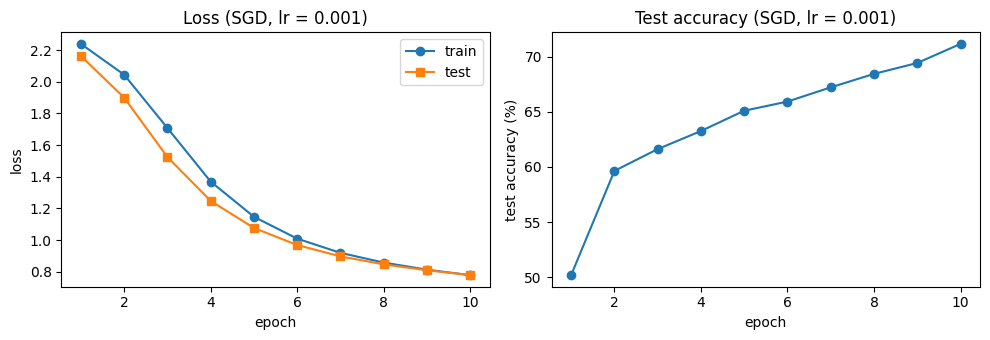

In [24]:
ep = range(1, len(hist_sgd["acc"]) + 1)                   # x축: 에포크 1~10
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))   # 그래프 2개를 가로로
ax1.plot(ep, hist_sgd["train_loss"], "o-", label="train") # 학습 손실 (에포크 평균)
ax1.plot(ep, hist_sgd["test_loss"], "s-", label="test")   # 테스트 손실
ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend()  # 꾸미기 (영문)
ax1.set_title("Loss (SGD, lr = 0.001)")                   # 제목
ax2.plot(ep, [100 * a for a in hist_sgd["acc"]], "o-")    # 테스트 정확도 (%)
ax2.set_xlabel("epoch"); ax2.set_ylabel("test accuracy (%)")  # 꾸미기 (영문)
ax2.set_title("Test accuracy (SGD, lr = 0.001)")          # 제목
plt.tight_layout()                                        # 간격 정리
plt.show()                                                # 그리기

🔍 **결과 읽는 법**
- 손실은 꾸준히 줄고 정확도는 꾸준히 오릅니다 — 학습이 **제대로** 되고 있습니다. (에포크 1 약 50 % → 5 약 65 % → 10 약 71 %)
- 흔히 이 모델에서 기대하는 "~88 %" 는 학습이 더 빠른 설정에서 볼 수 있는 값이고, 이 설정(SGD, 학습률 0.001)에서는 **약 71 %** 가 실제로 측정되는 정상적인 결과입니다.
- 곡선이 아직 오르는 중이죠? 학습률이 작아서 **천천히** 내려가는 중입니다. 수십 에포크를 더 학습하면 계속 오르지만, 더 빠른 방법이 있습니다 → 5장 실험실

**📝 1분 퀴즈** ① 학습 루프 4단계를 순서대로 말해 보세요. ② 시험(`test`) 때 `torch.no_grad()` 를 쓰는 이유는?
<details><summary>정답 보기</summary>

① 순전파 `model(X)` → 오차 `loss_fn(pred, y)` → 역전파 `zero_grad()` + `backward()` → 업데이트 `step()`
② 시험 때는 가중치를 고치지 않으므로 기울기가 필요 없습니다. 미분 추적을 끄면 더 빠르고 메모리도 아낍니다.
</details>

---
## 5. 실험실 — 71 % 에서 88 % 로!  🎬 EP5

### 5-1. ✋ 먼저 예측해 보세요 — 학습률을 100배 키우면?
SGD 의 학습률을 0.001 → **0.1** 로 키우면 어떻게 될까요?
(가) 더 빨리 학습한다 (나) 걸음이 너무 커서 학습이 망가진다 (다) 별 차이 없다

공정하게 비교하려고 **같은 초기 가중치(씨앗 0) · 같은 섞는 순서**로 시작하고 학습률만 바꿉니다. 시간을 아끼려고 **5 에포크**만 학습합니다. ⏸ CPU 에서 약 1분

In [25]:
torch.manual_seed(0)                                     # 🎲 같은 초기 가중치
g.manual_seed(0)                                         # 🎲 같은 섞는 순서
model_lr = NeuralNetwork().to(device)                    # 새 모델
opt_lr = torch.optim.SGD(model_lr.parameters(), lr=0.1)  # 학습률만 100배! (0.001 → 0.1)
hist_lr = fit(model_lr, opt_lr, epochs=5)                # 5 에포크만
check_range("SGD lr=0.1 · 5 에포크 정확도", hist_lr["acc"][-1], 0.80, 0.92)  # ✅

에포크  1 | 학습 손실 0.651 | 테스트 손실 0.467 · 정확도 83.0%


에포크  2 | 학습 손실 0.424 | 테스트 손실 0.459 · 정확도 83.4%


에포크  3 | 학습 손실 0.374 | 테스트 손실 0.435 · 정확도 84.1%


에포크  4 | 학습 손실 0.346 | 테스트 손실 0.358 · 정확도 87.0%


에포크  5 | 학습 손실 0.325 | 테스트 손실 0.367 · 정확도 86.9%
⏱ 25초 (5 에포크)
✅ SGD lr=0.1 · 5 에포크 정확도: 0.8689 (기대 범위 0.8 ~ 0.92)


🔍 정답은 **(가)** — 단 1 에포크 만에 약 83 %, 5 에포크에 약 87 % 입니다.
지난 실습(XOR)의 학습률 실험을 떠올려 보세요. 너무 작으면 제자리걸음, 너무 크면 엉뚱한 곳에 머물렀죠. **알맞은 학습률은 문제마다 다릅니다** — 이 문제에서는 0.001 이 너무 작았던 것입니다. (에포크마다 정확도가 조금씩 오르락내리락하는 것은 큰 걸음 때문에 생기는 흔들림입니다)

### 5-2. 최적화기 바꾸기 — Adam
이번에는 학습률을 강의노트와 **같은 0.001** 로 두고, 최적화기만 `Adam` 으로 바꿉니다. Adam 은 가중치마다 걸음 크기를 알아서 조절하는 "똑똑한 경사하강법"입니다 (지난 실습 6-4). 다음 실습(CNN)에서도 Adam 을 씁니다. ⏸ CPU 에서 약 1분

In [26]:
torch.manual_seed(0)                                     # 🎲 같은 초기 가중치
g.manual_seed(0)                                         # 🎲 같은 섞는 순서
model_adam = NeuralNetwork().to(device)                  # 새 모델
opt_adam = torch.optim.Adam(model_adam.parameters(), lr=0.001)  # 학습률 그대로, Adam 으로
hist_adam = fit(model_adam, opt_adam, epochs=5)          # 5 에포크만
check_range("Adam · 5 에포크 정확도", hist_adam["acc"][-1], 0.83, 0.93)  # ✅

에포크  1 | 학습 손실 0.489 | 테스트 손실 0.407 · 정확도 85.3%


에포크  2 | 학습 손실 0.358 | 테스트 손실 0.377 · 정확도 86.3%


에포크  3 | 학습 손실 0.321 | 테스트 손실 0.369 · 정확도 86.2%


에포크  4 | 학습 손실 0.297 | 테스트 손실 0.346 · 정확도 87.3%


에포크  5 | 학습 손실 0.277 | 테스트 손실 0.336 · 정확도 88.1%
⏱ 103초 (5 에포크)
✅ Adam · 5 에포크 정확도: 0.8814 (기대 범위 0.83 ~ 0.93)


### 5-3. 한 그래프로 비교
> 💡 **새 파이썬 문법 — `딕셔너리.items()`**
> 딕셔너리에서 **(이름표, 값)** 쌍을 하나씩 꺼냅니다. 실험 이름과 기록을 함께 꺼내 그래프를 그립니다.

SGD lr=0.001   10 에포크 → 71.2 %
SGD lr=0.1      5 에포크 → 86.9 %
Adam lr=0.001   5 에포크 → 88.1 %


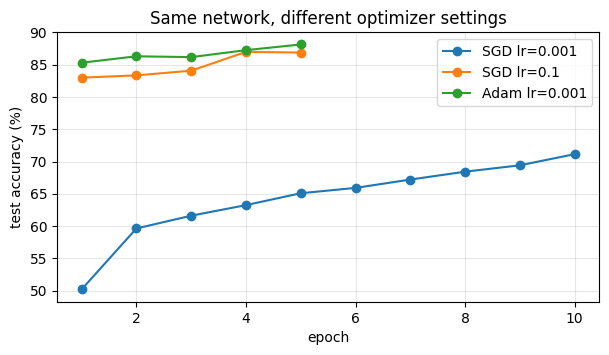

In [27]:
runs = {"SGD lr=0.001": hist_sgd,     # 강의노트 설정 (10 에포크)
        "SGD lr=0.1": hist_lr,        # 학습률 100배 (5 에포크)
        "Adam lr=0.001": hist_adam}   # Adam (5 에포크)
plt.figure(figsize=(7, 3.5))                                  # 그래프 크기
for name, h in runs.items():                                  # 실험마다 (이름, 기록)
    acc = [100 * a for a in h["acc"]]                         # 정확도 → %
    plt.plot(range(1, len(acc) + 1), acc, "o-", label=name)   # 에포크별 정확도
    print(f"{name:14s} {len(acc):2d} 에포크 → {acc[-1]:.1f} %")  # 마지막 정확도
plt.xlabel("epoch"); plt.ylabel("test accuracy (%)")         # 축 이름 (영문)
plt.title("Same network, different optimizer settings")      # 제목
plt.legend(); plt.grid(alpha=0.3)                            # 범례 · 연한 격자
plt.show()                                                   # 그리기

🔍 **결과 읽는 법** — 같은 신경망 · 같은 데이터 · 같은 시작점인데, **학습률이나 최적화기**만 바꿨더니 5 에포크 만에 85 % 를 넘었습니다. 흔히 말하는 "~88 %" 가 바로 이런 설정에서 볼 수 있는 값입니다.
학습 루프 4단계의 뼈대는 그대로 — **부품(설정)만 바꿨을 뿐**입니다.

---
## 6. 저장 · 불러오기 · 예측  🎬 EP5

### 6-1. 모델 저장하고 불러오기
학습에는 시간이 걸리니, 학습한 가중치는 파일로 저장해 두고 필요할 때 불러 씁니다. 가장 좋았던 Adam 모델을 저장합니다.
- `model.state_dict()` : 가중치 모음 (지난 실습 5-2 에서 시점별 가중치를 저장할 때 썼죠)
- `torch.save(가중치 모음, 파일)` → `torch.load(파일)` → 새 모델에 `load_state_dict()`
- `map_location=device` : 저장한 장치와 지금 장치가 달라도(GPU ↔ CPU) 지금 장치로 불러오기 · `weights_only=True` : 가중치(숫자)만 안전하게 불러오기

In [28]:
PATH = "fashion_mnist_model.pth"             # 저장할 파일 (.pth = PyTorch 파일)
torch.save(model_adam.state_dict(), PATH)    # 가중치 모음 → 파일
print(f"저장: {PATH} ({os.path.getsize(PATH) / 1e6:.1f} MB)")  # 669,706개 × 4바이트
loaded = NeuralNetwork().to(device)          # 빈 설계도로 새 모델 (아직 랜덤 가중치)
state = torch.load(PATH, map_location=device, weights_only=True)  # 파일 → 가중치 모음
loaded.load_state_dict(state)                # 새 모델에 넣기
loaded.eval()                                # 평가 모드 (강의노트처럼 습관적으로)
Xt, yt = next(iter(test_dataloader))         # 테스트 첫 배치 64장
with torch.no_grad():                        # 계산기 모드
    out_new = loaded(Xt.to(device))          # 불러온 모델의 점수
    out_old = model_adam(Xt.to(device))      # 원래 모델의 점수
check("불러온 모델 출력 = 원래 모델 출력", out_new.cpu(), out_old.cpu(), tol=1e-6)  # ✅
_, acc_loaded = test(test_dataloader, loaded, loss_fn)  # 1만 장 시험 (_ = 안 쓰는 값)
check("불러온 모델 정확도 = 원래 모델", acc_loaded, hist_adam["acc"][-1], tol=0)  # ✅

저장: fashion_mnist_model.pth (2.7 MB)


✅ 불러온 모델 출력 = 원래 모델 출력: 최대 차이 0.000000 (허용 0.000001)


✅ 불러온 모델 정확도 = 원래 모델: 최대 차이 0.000000 (허용 0)


🔍 불러온 모델은 원래 모델과 출력이 **완전히 같고**, 1만 장 정확도도 같습니다. 파일 크기 약 2.7 MB = 가중치 669,706개 × 4바이트(float32). Colab 에서는 왼쪽 📁(파일) 탭에서 `fashion_mnist_model.pth` 를 내려받을 수 있습니다.

### 6-2. 한 장 예측하기
강의노트의 예측 예제입니다. 신경망은 항상 **묶음(배치)** 으로 받기 때문에, 한 장도 `unsqueeze(0)` 으로 맨 앞에 배치 차원을 붙여 `[1, 1, 28, 28]` (1장짜리 배치)로 넣습니다.

예측: "Ankle boot" (확률 85.3%)
정답: "Ankle boot"


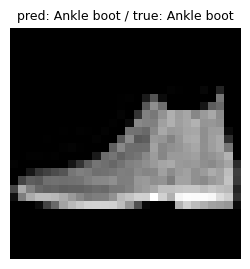

In [29]:
x, y_true = test_data[0]                          # 테스트 0번 이미지와 정답 번호
with torch.no_grad():                             # 계산기 모드
    out = loaded(x.unsqueeze(0).to(device))       # 📐 [1, 28, 28] → [1, 1, 28, 28]
pred_id = out.argmax(1).item()                    # 가장 큰 점수의 번호 (.item(): 숫자로)
prob = out.softmax(dim=1)[0, pred_id].item()      # 그 클래스의 확률
print(f'예측: "{class_names[pred_id]}" (확률 {prob:.1%})')  # 예측한 옷 이름
print(f'정답: "{class_names[y_true]}"')           # 정답 옷 이름
plt.figure(figsize=(3, 3))                        # 작은 그림판
plt.imshow(x.squeeze(), cmap="gray")              # 📐 (1, 28, 28) → (28, 28) 흑백 그림
title = f"pred: {class_names[pred_id]} / true: {class_names[y_true]}"  # 제목 (영문)
plt.title(title, fontsize=9)                      # 제목 달기
plt.axis("off")                                   # 눈금 숨기기
plt.show()                                        # 그리기

### 6-3. 16장 한꺼번에 — 맞으면 초록, 틀리면 빨강
테스트 첫 배치의 앞 16장입니다. 제목은 **예측한 옷 이름**입니다. 틀린 것은 아래에 🔸 로 따로 적습니다.
(그림을 그리는 코드입니다 — 결과 그림만 보셔도 됩니다)

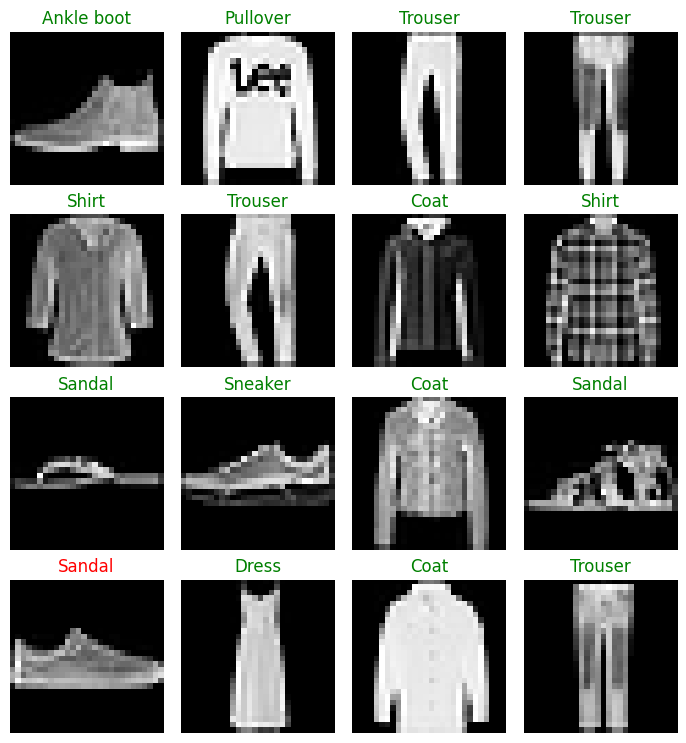

🔸 12번: 예측 Sandal / 정답 Sneaker


In [30]:
Xt, yt = next(iter(test_dataloader))              # 테스트 첫 배치 (앞 16장 사용)
with torch.no_grad():                             # 계산기 모드
    preds = loaded(Xt.to(device)).argmax(1).cpu()  # 예측 번호 64개 (그림용으로 CPU 로)
fig, axes = plt.subplots(4, 4, figsize=(7, 7.5))  # 4×4 칸의 그림판
for i, ax in enumerate(axes.flat):                # 16칸에 차례로
    color = "green" if preds[i] == yt[i] else "red"  # 맞으면 초록, 틀리면 빨강
    ax.imshow(Xt[i].squeeze(), cmap="gray")       # 이미지
    ax.set_title(class_names[preds[i]], color=color)  # 제목 = 예측한 옷 이름
    ax.axis("off")                                # 눈금 숨기기
plt.tight_layout(); plt.show()                    # 간격 정리하고 그리기
for i in range(16):                               # 틀린 것만 글로 확인
    if preds[i] != yt[i]:                         # 예측 ≠ 정답 이면
        p, t = class_names[preds[i]], class_names[yt[i]]  # 예측 이름, 정답 이름
        print(f"🔸 {i}번: 예측 {p} / 정답 {t}")      # 실패 사례

### 6-4. (선택) 옷 종류별 정확도 — 무엇을 헷갈릴까?
시험용 1만 장은 옷 종류마다 정확히 1,000장씩입니다. 종류마다 몇 장을 맞혔는지 세어 봅니다.

In [31]:
correct = torch.zeros(10)                            # 종류별 맞힌 장 수
with torch.no_grad():                                # 계산기 모드
    for X, y in test_dataloader:                     # 시험용 1만 장
        pred = loaded(X.to(device)).argmax(1).cpu()  # 예측 번호 (CPU 로)
        for c in range(10):                          # 종류마다
            correct[c] += ((y == c) & (pred == c)).sum()  # 정답도 c, 예측도 c 인 장 수
acc_c = correct / 1000                               # 종류별 정확도 (각 1,000장)
for c in acc_c.argsort():                            # 정확도가 낮은 종류부터
    bar = "█" * int(acc_c[c] * 40)                   # 글자로 그린 막대
    print(f"{class_names[c]:12s} {acc_c[c]:6.1%} {bar}")  # 이름 · 정확도 · 막대

Shirt         56.5% ██████████████████████
Pullover      82.8% █████████████████████████████████
Coat          83.3% █████████████████████████████████
Dress         88.8% ███████████████████████████████████
T-shirt/top   89.6% ███████████████████████████████████
Sandal        95.5% ██████████████████████████████████████
Ankle boot    95.5% ██████████████████████████████████████
Sneaker       96.0% ██████████████████████████████████████
Trouser       96.2% ██████████████████████████████████████
Bag           97.2% ██████████████████████████████████████


🔍 **결과 읽는 법** — 바지 · 가방 · 샌들처럼 모양이 뚜렷한 종류는 95 % 를 넘지만, **셔츠(Shirt)** 는 60 % 에도 못 미쳐 가장 낮고 스웨터 · 코트도 80 % 대입니다. 셔츠는 1-3 에서 우리도 헷갈렸던 티셔츠 · 스웨터 · 코트와 비슷하게 생겼기 때문입니다. 이미지를 한 줄로 펼쳐 버리는 이 신경망은 '가까운 픽셀끼리 만드는 모양'을 잘 활용하지 못합니다 → 다음 실습의 **합성곱 신경망(CNN)** 이 이 문제를 다룹니다.

### 6-5. 🏆 도전 과제
1. **학습률 실험** — 5-1 셀을 복사해 `lr` 을 0.01 · 0.0001 로 바꿔 5 에포크씩 학습하고, 0.001 · 0.1 과 정확도를 비교해 보세요.
2. **배치 크기 · 은닉노드** — `batch_size` 를 32 · 128 로, 은닉노드를 512 → 256 · 1024 로 바꾸면 1 에포크 시간(⏱)과 정확도가 어떻게 달라지나요? (힌트: 배치 크기를 바꾸면 2장의 `DataLoader` 셀부터 다시 실행)
3. **혼동 행렬** — 셔츠(6번)를 주로 무엇으로 착각하는지 세어 보세요. (힌트: 6-4 셀에서 `(y == 6) & (pred == c)` 를 클래스 c 마다 세기)

---
## 7. 핵심 요약

### 이론 ↔ 코드 대응표 (FashionMNIST 판)
| 이론 | PyTorch 코드 |
|---|---|
| 데이터 (입력 이미지 · 정답) | `datasets.FashionMNIST(..., transform=ToTensor())` → `(이미지, 번호)` |
| Batch size · 미니배치 | `DataLoader(training_data, batch_size=64, shuffle=True)` |
| Epoch (전체 데이터 한 바퀴) | `for epoch in range(epochs):` — 1 에포크 = 배치 938개 |
| 입력층 784개 (픽셀) | `nn.Flatten()` : `[N, 1, 28, 28]` → `[N, 784]` |
| 은닉층 · 활성화 함수 | `nn.Linear(784, 512)`, `nn.ReLU()` |
| 출력층 10개 (클래스 수) · 로짓 | `nn.Linear(512, 10)` |
| 소프트맥스 + 크로스 엔트로피 | `nn.CrossEntropyLoss()` (소프트맥스 포함) |
| 오류역전파 ∂L/∂w | `loss.backward()` |
| 경사하강법 w ← w − α·∂L/∂w | `optimizer.step()` (`SGD`, `Adam`) |
| 학습률 α | `lr=0.001` |
| 예측 · 정확도 | `pred.argmax(1)`, `(pred.argmax(1) == y).sum()` |

### 학습 루프 4단계 (지난 실습과 똑같이!)
```python
for X, y in dataloader:      # 미니배치(64장)마다
    pred = model(X)          # 1️⃣ 순전파
    loss = loss_fn(pred, y)  # 2️⃣ 오차 계산
    optimizer.zero_grad()    # 3️⃣ 역전파: 기울기 지우고
    loss.backward()          #           기울기 계산
    optimizer.step()         # 4️⃣ 가중치 업데이트
```

### ⚠️ 자주 하는 실수 5가지
1. `transform=ToTensor()` 를 빠뜨림 → 이미지가 텐서가 아니라서 오류
2. 모델 끝에 소프트맥스를 또 넣음 → `CrossEntropyLoss` 안의 소프트맥스와 겹쳐 학습이 잘 안 됨
3. 모델과 데이터의 장치가 다름 (`.to(device)` 를 빠뜨림) → GPU 에서 "Expected all tensors to be on the same device" 오류
4. 시험할 때 `model.eval()` · `torch.no_grad()` 를 빠뜨림 → 느리고 메모리 낭비 (Dropout 이 있는 모델은 결과도 달라짐)
5. 학습률이 너무 작음 → 오류 없이 **천천히** 학습되어 "안 되는 것처럼" 보임 (4장!)

### 지난 실습(XOR)과 무엇이 달라졌나?
| | XOR | FashionMNIST |
|---|---|---|
| 데이터 | 4개 (직접 입력) | 6만 장 (`Dataset`) |
| 업데이트 단위 | 한 샘플씩 | 미니배치 64장 (`DataLoader`) |
| 신경망 | 2 – 2 – 1, 시그모이드 | 784 – 512 – 512 – 10, ReLU |
| 가중치 수 | 9개 | 669,706개 |
| 비용함수 | ½(t − o)² | 크로스 엔트로피 (소프트맥스 포함) |
| 학습 루프 | **4단계** | **4단계 (그대로!)** |

### 다음 실습 예고
이 신경망은 이미지를 한 줄로 펼쳐서 보기 때문에, 가까운 픽셀끼리 만드는 **모양**을 잘 활용하지 못합니다. 다음 실습에서는 이미지를 **2차원 그대로** 보는 **합성곱 신경망(CNN)** 을 만듭니다. 손글씨 숫자(MNIST)로 익힌 뒤, 선택 실습에서 같은 FashionMNIST 에도 적용해 이 신경망보다 얼마나 더 잘 맞히는지 비교합니다.